In [ ]:
import random
random.seed(42)

import torch
import time
import os

import numpy as np
import pyomo.environ as pyo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from pyomo.environ import *
from utils import generate_simple_synthetic_data, const_embed, generate_data_by_ids, plot_mean_sd
from trainer import Trainer

np.random.seed(43)

DATA_BY_ID = True

In [ ]:
if DATA_BY_ID:
    print("Loading data by IDs...")
    df = generate_data_by_ids(n_ids=100, n_prices_per_id=100, k=0.2)
    X = df[['id', 'x1', 'x2', 'price']]
    y = df['y']
    #y = round(df['y'])
    print(X.head())
    print(y.head())

else:
    X, y, true_mean, true_std = generate_simple_synthetic_data(n_samples=1000)
    print(X.head())
    print(y.head())


Loading data by IDs...
   id       x1        x2      price
0   1  0.37454  0.031429  22.840633
1   1  0.37454  0.031429  11.682799
2   1  0.37454  0.031429  13.232574
3   1  0.37454  0.031429  27.971084
4   1  0.37454  0.031429  22.128581
0    0.960657
1    2.497850
2    4.394927
3    0.566920
4    0.000000
Name: y, dtype: float64


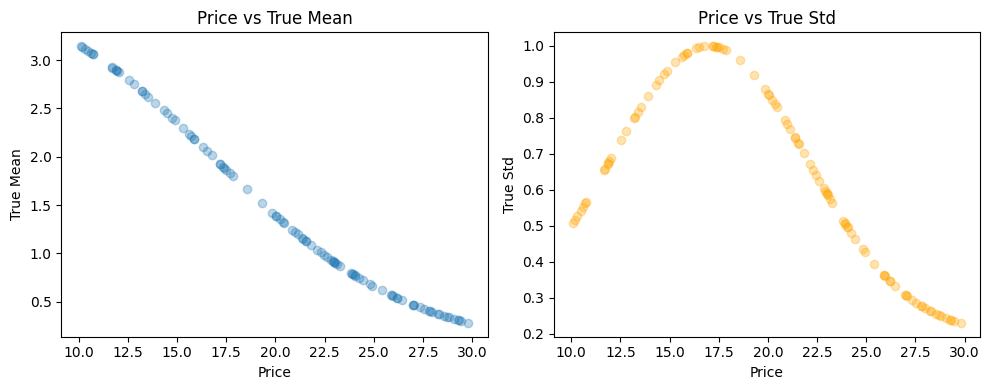

In [3]:
plot_mean_sd(df, id_col='id', price_col='price', id=1, save_path="./imgs/true_mean_sd.png")

In [ ]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

config = {
    # Model config
    'hidden_layers': 0,
    'hidden_size': 32,
    'drop': 0.018253331815335814,

    # Training config
    'lr': 0.0014570127381474667,
    'wd': 0.0007924986676083113,
    'batchsize': 128,
    'iters': 5000,
    'patience': 500
}

trainer = Trainer(X, y, config, device=device)

if not DATA_BY_ID:
    trainer.create_data_partitions(val_size=0.2, test_size=0.2, random_state=42)
else:
    trainer = Trainer(X, y, config, device=device, id_col='id')
    trainer.create_temporal_partitions_by_id(val_size=0.2, test_size=0.2)
    

print("X_train shape: ", trainer.X_train.shape)
print("X_val shape: ", trainer.X_val.shape)
print("X_test shape: ", trainer.X_test.shape)

self.X_train:            price        x1        x2
0     22.840633  0.374540  0.031429
1     11.682799  0.374540  0.031429
2     13.232574  0.374540  0.031429
3     27.971084  0.374540  0.031429
4     22.128581  0.374540  0.031429
...         ...       ...       ...
9955  18.695035  0.107891  0.779876
9956  11.193477  0.107891  0.779876
9957  19.443672  0.107891  0.779876
9958  20.335213  0.107891  0.779876
9959  27.093664  0.107891  0.779876

[6000 rows x 3 columns]
X_train shape:  (6000, 3)
X_val shape:  (2000, 3)
X_test shape:  (2000, 3)


In [5]:
trainer.X_train

,price,x1,x2
0,0.495280,-0.323112,-1.599230
1,-1.436192,-0.323112,-1.599230
2,-1.167919,-0.323112,-1.599230
3,1.383384,-0.323112,-1.599230
4,0.372021,-0.323112,-1.599230
...,...,...,...
5995,-0.222342,-1.223958,0.967089
5996,-1.520896,-1.223958,0.967089
5997,-0.092749,-1.223958,0.967089
5998,0.061580,-1.223958,0.967089


In [6]:
trainer.model

distModel(
  (input_layer): Linear(in_features=3, out_features=32, bias=True)
  (hidden_layers): ModuleList()
  (output_mean_layer): Linear(in_features=32, out_features=1, bias=True)
  (output_sd_layer): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.018253331815335814, inplace=False)
)

In [7]:
trainer.train()

trainer.test()

Validation loss improved from inf to 2136.3782 in epoch 1. Saving model...
Epoch 1/5000 - Train Loss: 51861.3437, Val Loss: 2136.3782
Validation loss improved from 2136.3782 to 6.9943 in epoch 2. Saving model...
Validation loss improved from 6.9943 to 6.7231 in epoch 3. Saving model...
Validation loss improved from 6.7231 to 6.5120 in epoch 4. Saving model...
Validation loss improved from 6.5120 to 6.3439 in epoch 5. Saving model...
Validation loss improved from 6.3439 to 5.1208 in epoch 6. Saving model...
Validation loss improved from 5.1208 to 4.7598 in epoch 7. Saving model...
Validation loss improved from 4.7598 to 4.1098 in epoch 8. Saving model...
Validation loss improved from 4.1098 to 3.9858 in epoch 9. Saving model...
Validation loss improved from 3.9858 to 3.2084 in epoch 10. Saving model...
Validation loss improved from 3.2084 to 2.8743 in epoch 11. Saving model...
Epoch 11/5000 - Train Loss: 3.1623, Val Loss: 2.8743
Validation loss improved from 2.8743 to 2.8198 in epoch 12

In [8]:
#trainer.predict(X=trainer.X_test)

In [9]:
trainer.evaluate_gaussian_nll()
trainer.evaluate_standardized_residuals()

Baseline Gaussian NLL Loss: 0.5103
Model Gaussian NLL Loss: -0.9185
KS test against N(0,1): statistic = 0.0123, p-value = 0.9208
✅ The standardized residuals do not significantly differ from a standard normal distribution — model variance estimates appear well-calibrated.
Saved: residual_diagnostics\z_histogram.png
Saved: residual_diagnostics\z_qqplot.png


(np.float64(0.012260787844164456), np.float64(0.9208069115114201))

In [11]:
cons = trainer.constraint_build()
cons.to_csv('constraints.csv')

In [12]:
cons = pd.read_csv('constraints.csv', index_col=0)
pd.set_option('display.precision', 10)
cons

,intercept,layer,node,node_0,node_1,node_2,node_3,node_4,node_5,node_6,...,node_22,node_23,node_24,node_25,node_26,node_27,node_28,node_29,node_30,node_31
0,0.236563200,0,0,-0.375891570,0.287691560,0.187554080,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-0.442527560,0,1,0.405631900,0.005584030,0.011868079,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.087639940,0,2,0.134854840,-0.034302015,-0.045793198,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.136304400,0,3,0.224813150,-0.048673224,0.008262100,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,-0.486302900,0,4,0.224073400,-0.083612020,-0.222421510,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.233613900,0,5,-0.280962230,0.087428436,0.041268356,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,-0.077736735,0,6,-0.099627340,0.013553795,-0.326507750,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,0.114918440,0,7,0.139756660,-0.025248913,-0.027412176,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,0.043928800,0,8,0.097631454,-0.178091970,-0.051304284,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.101007100,0,9,0.123979370,-0.022943797,-0.021745227,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Adapted from DistCL, VPP.ipynb: vpp_opt.
# Retains scenario indexing, the expected-value objective, and contextual constraints.
# Modifications: pricing revenue, integer demand, and price limits replace the VPP model.
# Source: https://github.com/antonioalcantaramata/DistCL/tree/main
def model_definition(contextual_var, n_sc, n_preds, integer_demand=False, mean_price=None, mean_price_by_id=None, P_max=30):
    model = pyo.ConcreteModel()
    
    model.N = pyo.RangeSet(0,n_preds-1)
    model.W = pyo.RangeSet(1,n_sc) # scenarios

    if mean_price_by_id is not None:
        model.mean_price_by_id = pyo.Param(model.N, initialize=mean_price_by_id)


    pi = [1/n_sc for i in range(n_sc)]

    model.var_ind = pyo.Set(initialize=contextual_var.columns.sort_values())

    model.x = pyo.Var(model.var_ind, model.N) # price

    model.y = pyo.Var(pyo.Any, dense=False, domain=pyo.Reals)
    if integer_demand:
        model.y_int = pyo.Var(model.N, model.W, domain=pyo.Integers)

    model.rent = pyo.Var(model.W, within=pyo.Reals) # revenue per scenario

    #definition of the objective function
    def obj_expression(model):
        return sum(pi[w-1] * model.rent[w] for w in model.W)
    model.OBJ = pyo.Objective(rule=obj_expression, sense=pyo.maximize)

    #################
    ## Constraints ##
    #################

    if integer_demand:
        # rentability constraint integer y
        def rent_expression_int(model, w):
            return model.rent[w] == sum(model.y_int[n, w]*model.x['price',n] for n in model.N)
        model.rent_expression_int = pyo.Constraint(model.W, rule=rent_expression_int)  

        # integer demand constraint
        # Upper bound constraint
        def round_y_upper(model, n, w):
            return model.y_int[n, w] <= model.y['demand', n, w] + 0.5
        model.round_y_upper = pyo.Constraint(model.N, model.W, rule=round_y_upper)

        # Lower bound constraint
        def round_y_lower(model, n, w):
            return model.y_int[n, w] >= model.y['demand', n, w] - 0.5
        model.round_y_lower = pyo.Constraint(model.N, model.W, rule=round_y_lower)
    else:
        # rentability constraint continuous y
        def rent_expression(model, w):
            return model.rent[w] == sum(model.y['demand', n, w]*model.x['price',n] for n in model.N)
        model.rent_expression = pyo.Constraint(model.W, rule=rent_expression)

    
    #constraint for fixing contextual information
    def contextual_info(model,x_ind,n):
        if x_ind=='price':
            return pyo.Constraint.Skip
        else:
            return model.x[x_ind,n] == contextual_var.loc[n,x_ind]
    model.const9 = pyo.Constraint(model.var_ind, model.N, rule=contextual_info)

    # max price constraint for each price
    def max_price_expression(model, n):
        return model.x['price', n] <= P_max

    model.max_price_expression = pyo.Constraint(model.N, rule=max_price_expression)

    def min_price_expression(model, n):
        return model.x['price', n] >= 0
    model.min_price_expression = pyo.Constraint(model.N, rule=min_price_expression)

    if mean_price is not None:
        # price increase of 2% with respect the mean price
        def price_increase_expression(model):
            return sum(model.x['price', n] for n in model.N)/len(model.N) >= mean_price * 1.02
        model.price_increase_expression = pyo.Constraint(rule=price_increase_expression)

        if mean_price_by_id is not None:
            # price can't increase more than 5% with respect the mean price offered to this client in the past
            def price_increase_by_id_expression(model, n):
                return model.x['price', n] <= model.mean_price_by_id[n] * 1.05

            model.price_increase_by_id_expression = pyo.Constraint(model.N, rule=price_increase_by_id_expression)

    return model


In [ ]:
n_preds = 5
n_sc =  50

if DATA_BY_ID:
    # Get only training data
    train_df = trainer.X.loc[trainer.train_indices].copy()

    # Get the IDs present in the training set
    train_ids = train_df[trainer.id_col].unique()

    # Select the first row per ID from training set (simulate "oldest" observation per ID)
    contextual_var = train_df.drop_duplicates(subset=trainer.id_col, keep='first').drop(columns=trainer.id_col)[:n_preds]

    # Compute mean price per ID from training data
    mean_price_by_id = train_df.groupby(trainer.id_col)['price'].mean()

    # Restrict to selected IDs (if you want only the first `n_preds` ones)
    ids = train_ids[:n_preds]
    mean_price_by_id = mean_price_by_id.loc[ids]

    # Convert to dict using enumeration (index as key)
    mean_price_by_id = dict(enumerate(mean_price_by_id))

    # Compute global mean price from training data
    mean_price = train_df[train_df[trainer.id_col].isin(ids)]['price'].mean()

    # Print results
    print("mean_price_by_id:", mean_price_by_id)
    print("mean_price:", mean_price)
else:
    contextual_var = trainer.X[trainer.X.index.isin(trainer.test_indices)]
    contextual_var = contextual_var.iloc[:n_preds]

contextual_var.reset_index(drop=True, inplace=True)
print(contextual_var)

mean_price_by_id: {0: 20.22528938084565, 1: 19.978241274399497, 2: 19.076066368735088, 3: 19.007858143576374, 4: 21.339243173505675}
mean_price: 19.92533966821246
           price            x1            x2
0  22.8406329231  0.3745401188  0.0314291857
1  11.1511752003  0.9507143064  0.6364104113
2  15.6755181160  0.7319939418  0.3143559811
3  10.3942107551  0.5986584842  0.5085706912
4  27.7749615974  0.1560186404  0.9075664739


In [67]:
contextual_var['price'].mean()

np.float64(17.56729971837199)

In [68]:
mean_price_by_id

{0: 20.22528938084565,
 1: 19.978241274399497,
 2: 19.076066368735088,
 3: 19.007858143576374,
 4: 21.339243173505675}

In [ ]:
model = model_definition(contextual_var, n_sc, n_preds, mean_price=mean_price, mean_price_by_id=mean_price_by_id, integer_demand=True)
const_embed(model=trainer, opt_model=model, constaints=cons, outcome='demand', n_scenarios=n_sc, n_preds=n_preds)

In [87]:
start = time.time()            
opt = pyo.SolverFactory('gurobi_direct')
opt.options['threads'] = 0
opt.options['NonConvex'] = 2
results = opt.solve(model, tee=True)
end = time.time()
solve_time = end - start

print("Solve time:", solve_time)

Set parameter OutputFlag to value 1
Set parameter Threads to value 0
Set parameter NonConvex to value 2
Gurobi Optimizer version 12.0.2 build v12.0.2rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i5-13500, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 20 threads

Non-default parameters:
NonConvex  2

Optimize a model with 1266 rows, 895 columns and 3870 nonzeros
Model fingerprint: 0x2947ba9c
Model has 50 quadratic constraints
Variable types: 485 continuous, 410 integer (160 binary)
Coefficient statistics:
  Matrix range     [3e-03, 1e+03]
  QMatrix range    [1e+00, 1e+00]
  QLMatrix range   [1e+00, 1e+00]
  Objective range  [2e-02, 2e-02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [3e-02, 1e+03]
Presolve removed 732 rows and 617 columns
Presolve time: 0.01s
Presolved: 981 rows, 503 columns, 3604 nonzeros
Presolved model has 218 bilinear constraint(s)

Solving non-convex MIQCP

Variable types: 2

In [84]:
total = 0
for c in model.component_objects(Constraint, active=True):
    print(f"Constraint component: {c.name}")
    for index in c:
        total += 1
        print(f"  {index}: {c[index].expr}")
print(f"Total number of constraints: {total}")

Constraint component: rent_expression_int
  1: rent[1]  ==  y_int[0,1]*x[price,0] + y_int[1,1]*x[price,1] + y_int[2,1]*x[price,2] + y_int[3,1]*x[price,3] + y_int[4,1]*x[price,4]
  2: rent[2]  ==  y_int[0,2]*x[price,0] + y_int[1,2]*x[price,1] + y_int[2,2]*x[price,2] + y_int[3,2]*x[price,3] + y_int[4,2]*x[price,4]
  3: rent[3]  ==  y_int[0,3]*x[price,0] + y_int[1,3]*x[price,1] + y_int[2,3]*x[price,2] + y_int[3,3]*x[price,3] + y_int[4,3]*x[price,4]
  4: rent[4]  ==  y_int[0,4]*x[price,0] + y_int[1,4]*x[price,1] + y_int[2,4]*x[price,2] + y_int[3,4]*x[price,3] + y_int[4,4]*x[price,4]
  5: rent[5]  ==  y_int[0,5]*x[price,0] + y_int[1,5]*x[price,1] + y_int[2,5]*x[price,2] + y_int[3,5]*x[price,3] + y_int[4,5]*x[price,4]
  6: rent[6]  ==  y_int[0,6]*x[price,0] + y_int[1,6]*x[price,1] + y_int[2,6]*x[price,2] + y_int[3,6]*x[price,3] + y_int[4,6]*x[price,4]
  7: rent[7]  ==  y_int[0,7]*x[price,0] + y_int[1,7]*x[price,1] + y_int[2,7]*x[price,2] + y_int[3,7]*x[price,3] + y_int[4,7]*x[price,4]
  8: r

In [73]:
contextual_var

,price,x1,x2
0,22.8406329231,0.3745401188,0.0314291857
1,11.1511752003,0.9507143064,0.6364104113
2,15.6755181160,0.7319939418,0.3143559811
3,10.3942107551,0.5986584842,0.5085706912
4,27.7749615974,0.1560186404,0.9075664739


In [77]:
total_demand = 0
for x in range(n_sc):
    total_demand += value(model.y['demand', 4, x+1])
    print(value(model.y['demand', 4, x+1]))
print("Total demand for scenario 5:", total_demand)
print("Average demand for scenario 5:", total_demand/n_sc )

2.9491005472960765
2.032234921020871
2.421180383669551
3.2696523078243738
3.0186812391395774
1.10626719079063
2.40192098308892
1.6614845626575991
1.6938451182217744
2.039253982021468
1.8600649470242276
2.740854648179126
2.2748334404421904
1.8450278973866177
2.0616158831702203
1.9875424321060493
2.7676135641486406
1.6253173111907346
1.973689822562685
1.189075221518442
0.04700972211683285
2.202621944912054
2.3443420879494417
1.264319590275347
3.2890541280833006
0.7855494261786464
1.7939937477245056
1.637400441085617
2.7936293686051945
2.7509955737306884
1.8673949602652657
2.0174491992059416
1.1664274315720908
0.431661296526052
1.5293523597225562
1.8683371345851552
2.590284308429709
2.571521515232435
1.5028562213179366
1.5600128473193335
1.0583531878591839
0.8086393682954116
0.6162089941463855
3.0746233538402565
1.4206241503204178
1.468741704297406
0.9210531665999666
2.2858935660493103
0.6783054294527635
1.620220372234409
Total demand for scenario 5: 92.88613300139339
Average demand for s

In [88]:
total_price = 0
for n in model.N:
    print("&"*50)
    print("Establishment ", n)
    opt_price = value(model.x['price',n])
    total_price += opt_price
    total_demand = 0
    total_demand_int = 0
    for x in range(n_sc):
        total_demand += value(model.y['demand', n, x+1])
        total_demand_int += value(model.y_int[n, x+1])
        #print("demand: ", value(model.y['demand', 0, x+1]))
    print("Average demand: ", total_demand/n_sc)
    print("Average demand int: ", total_demand_int/n_sc)
    opt_mean = value(model.y['demand', n,'mean'])
    opt_sd = value(model.y['demand', n,'sd'])
    opt_profit = value(model.OBJ)
    opt_mean_unscaled = opt_mean * trainer.y_std[0] + trainer.y_mean[0]
    opt_sd_unscaled = opt_sd * trainer.y_std[0] 

    print(f"Optimal profit: {opt_profit}")
    print(f"Average price train: {mean_price_by_id[n]}")
    print(f"Optimal price: {opt_price}")
    print(f"Optimal mean (scaled): {opt_mean} → (unscaled): {opt_mean_unscaled}")
    print(f"Optimal sd (scaled): {opt_sd} → (unscaled): {opt_sd_unscaled}")
    print("&"*50)

print("Average price train: ", mean_price)
print("Average price opt: ", total_price/len(model.N))
print("Is average price higher than 2% of the mean price? ", (total_price/len(model.N)) >= mean_price * 1.02)

&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Establishment  0
Average demand:  1.2362907804211196
Average demand int:  1.18
Optimal profit: 314.7763846251502
Average price train: 20.22528938084565
Optimal price: 21.23655384988793
Optimal mean (scaled): -0.7571826792608239 → (unscaled): 1.142804209628145
Optimal sd (scaled): 0.2709108149841574 → (unscaled): 0.6651042599646648
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Establishment  1
Average demand:  5.882052143177901
Average demand int:  5.92
Optimal profit: 314.7763846251502
Average price train: 19.978241274399497
Optimal price: 18.27298759729121
Optimal mean (scaled): 1.1243370932155512 → (unscaled): 5.762061716771095
Optimal sd (scaled): 0.3477152272506658 → (unscaled): 0.8536642544614675
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Establishment  2
Average demand:  3.4971422474097147
Average demand int:  3.54
O

In [28]:
total_price = 0
for n in model.N:
    print("&"*50)
    print("Establishment ", n)
    opt_price = value(model.x['price',n])
    total_price += opt_price
    total_demand = 0
    total_demand_int = 0
    for x in range(n_sc):
        total_demand += value(model.y['demand', n, x+1])
        total_demand_int += value(model.y_int[n, x+1])
        print("demand: ", value(model.y['demand', 0, x+1]))
    print("Average demand: ", total_demand/n_sc)
    print("Average demand int: ", total_demand_int/n_sc)
    opt_mean = value(model.y['demand', n,'mean'])
    opt_sd = value(model.y['demand', n,'sd'])
    opt_profit = value(model.OBJ)
    opt_mean_unscaled = opt_mean * trainer.y_std[0] + trainer.y_mean[0]
    opt_sd_unscaled = opt_sd * trainer.y_std[0] 

    print(f"Optimal profit: {opt_profit}")
    print(f"Average price train: {mean_price_by_id[n]}")
    print(f"Optimal price: {opt_price}")
    print(f"Optimal mean (scaled): {opt_mean} → (unscaled): {opt_mean_unscaled}")
    print(f"Optimal sd (scaled): {opt_sd} → (unscaled): {opt_sd_unscaled}")
    print("&"*50)

print("Average price train: ", mean_price)
print("Average price opt: ", total_price/len(model.N))
print("Is average price higher than 2% of the mean price? ", (total_price/len(model.N)) >= mean_price * 1.02)

&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Establishment  0
demand:  2.335891582578535
demand:  1.4224796998968514
demand:  1.8099600428362133
demand:  2.655235855817976
demand:  2.405210170726794
demand:  0.5
demand:  1.7907731905434268
demand:  1.0531259220556295
demand:  1.0853645785560164
demand:  1.4294723207776874
demand:  1.2509582734383058
demand:  2.1284301254990448
demand:  1.664164374302895
demand:  1.2359778669034183
demand:  1.4517499868208603
demand:  1.377955563238723
demand:  2.155088243236025
demand:  1.0170949091055868
demand:  1.3641551351275039
demand:  0.5824961009341514
demand:  -0.5552673488661817
demand:  1.5922248924494833
demand:  1.7334111894989077
demand:  0.6574570314760166
demand:  2.6745645913079876
demand:  0.18049034799810237
demand:  1.1851359579169245
demand:  1.0291325230259705
demand:  2.1810060486888023
demand:  2.138532851170872
demand:  1.258260675232752
demand:  1.4077496744571925
demand:  0.5599336230086605
demand:  -0.17206471950712343

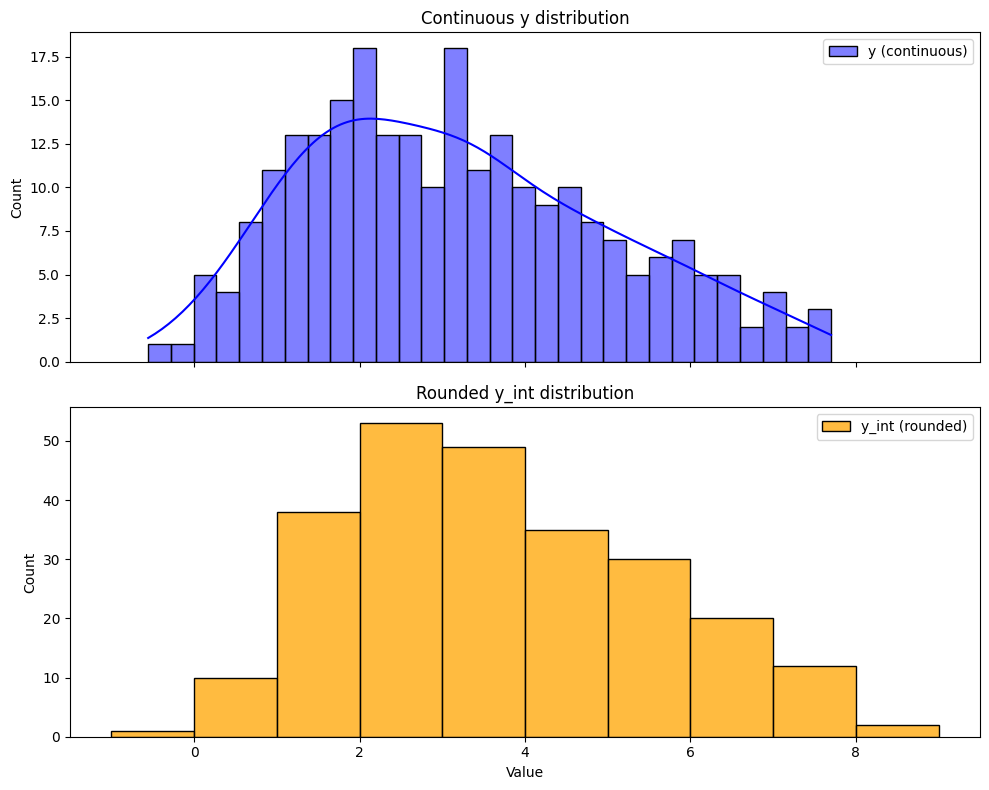

In [80]:
# ALL DEMANDS TOGETHER
y_vals = [pyo.value(model.y['demand', n, w]) for n in model.N for w in model.W]
y_int_vals = [pyo.value(model.y_int[n, w]) for n in model.N for w in model.W]

fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

sns.histplot(y_vals, kde=True, color='blue', label='y (continuous)', bins=30, ax=ax[0])
ax[0].legend()
ax[0].set_title('Continuous y distribution')

sns.histplot(y_int_vals, kde=False, color='orange', label='y_int (rounded)', 
             bins=range(int(min(y_int_vals)), int(max(y_int_vals))+2), ax=ax[1])
ax[1].legend()
ax[1].set_title('Rounded y_int distribution')

plt.xlabel('Value')
plt.tight_layout()
plt.savefig("imgs/distribution_y_y_int.png")
plt.show()

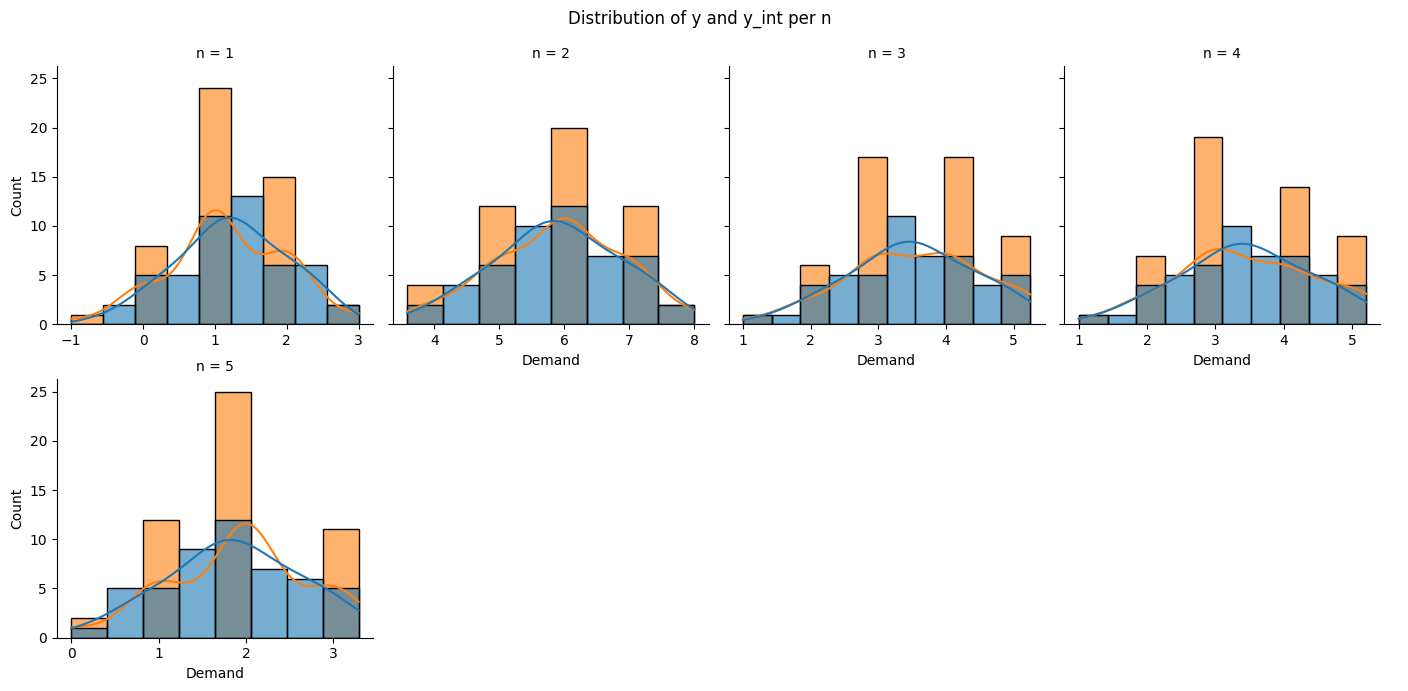

In [92]:
# DEMAND BY ID

# Create a DataFrame from your data
data = []
for n in model.N:
    for w in model.W:
        y_val = pyo.value(model.y['demand', n, w])
        y_int_val = pyo.value(model.y_int[n, w])
        data.append({'n': n+1, 'w': w, 'y': y_val, 'y_int': y_int_val})
df = pd.DataFrame(data)

# Melt the DataFrame to long format for seaborn
df_melted = df.melt(id_vars=['n', 'w'], value_vars=['y', 'y_int'], var_name='type', value_name='Demand')

# Plot using FacetGrid (one subplot per n)
g = sns.FacetGrid(df_melted, col='n', col_wrap=4, sharex=False, height=3.5)
g.map_dataframe(sns.histplot, x='Demand', hue='type', kde=True if 'y' in df_melted['type'].unique() else False, alpha=0.6)
g.add_legend()
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Distribution of y and y_int per n")
plt.savefig("imgs/distribution_y_y_int_by_n.png")
plt.show()


# EXPERIMENTS

In [ ]:
import matplotlib.ticker as mticker
def experiment_price_n_sc_solve_time(trainer, use_means=True, n_ids=10,end_range=100):
    # Configuration
    #test_ids = trainer.test_ids[:n_ids]

    test_df = trainer.X.loc[trainer.test_indices]
    available_test_ids = test_df[trainer.id_col].unique()

    if n_ids > len(available_test_ids):
        raise ValueError(f"Requested {n_ids} IDs but only {len(available_test_ids)} available in test set.")

    test_ids = available_test_ids[:n_ids]

    scenario_range = list(range(1, end_range, 5)) 

    filename = f"imgs/price_vs_n_sce_vs_solve_time_{'with_means' if use_means else 'no_means'}_{n_ids}_ids_{end_range}_n_sc.png"

    if os.path.exists(filename):
        print(f"Loading existing plot from {filename}")
        img = plt.imread(filename)
        plt.figure(figsize=(15, 16))
        plt.imshow(img)
        plt.axis('off')  # Hide axes
        plt.title("Loaded Plot Image")
        plt.show()
    else:
        # To store results
        results = []

        for i, test_id in enumerate(test_ids):
            print("&"*50)
            print(f"Processing ID: {test_id} ({i+1}/{len(test_ids)})")

            # --- Compute mean prices if needed ---
            if use_means:
                test_df = trainer.X.loc[trainer.test_indices]
                test_df = test_df[test_df['id'] == test_id]
                mean_price_by_id = test_df.mean()['price']
                mean_price_by_id = {0: mean_price_by_id}
                
                mean_price = test_df['price'].mean()
            else:
                mean_price = None
                mean_price_by_id = None
            
            # Build contextual_var for this single ID
            contextual_var = trainer.X[trainer.X['id'] == test_id]
            contextual_var = contextual_var.drop_duplicates(subset='id', keep='first').drop(columns='id')
            contextual_var.reset_index(drop=True, inplace=True)
            n_preds = 1  # Because we use one ID at a time

            for n_sc in scenario_range:
                # Define and solve model
                model = model_definition(contextual_var, n_sc, n_preds, mean_price=mean_price, mean_price_by_id=mean_price_by_id, integer_demand=True)
                const_embed(model=trainer, opt_model=model, constaints=cons, outcome='demand',
                            n_scenarios=n_sc, n_preds=n_preds)

                opt = pyo.SolverFactory('gurobi_direct')
                opt.options['threads'] = 0
                opt.options['NonConvex'] = 2

                start = time.time()
                results_obj = opt.solve(model, tee=False)
                end = time.time()

                price_val = pyo.value(model.x['price', 0])
                solve_time = end - start

                results.append({
                    'id': test_id,
                    'n': 0,
                    'n_sc': n_sc,
                    'price': price_val,
                    'solve_time': solve_time
                })
                print(price_val)
                print(f"n_sc={n_sc}: price={price_val:.4f}, time={solve_time:.4f}s")
            print("&"*50)

        # --- Convert to DataFrame ---
        df_results = pd.DataFrame(results)

        # --- Plot ---
        unique_ids = df_results['id'].unique()
        n_cols = 3
        n_rows = -(-len(unique_ids) // n_cols)  # Ceiling division

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4), sharex=False)
        axes = axes.flatten()

        for i, test_id in enumerate(unique_ids):
            ax1 = axes[i]
            ax2 = ax1.twinx()  # Create second y-axis

            data = df_results[df_results['id'] == test_id]
            data['price'] = data['price'].round(4)


            # Plot price
            ax1.plot(data['n_sc'], data['price'], color='blue', marker='o', label='Price')
            #ax1.yaxis.set_major_formatter(mticker.ScalarFormatter(useOffset=False))

            ax1.set_ylabel('Price', color='blue')
            ax1.tick_params(axis='y', labelcolor='blue')
            ax1.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.4f'))

            # Plot solve time
            ax2.plot(data['n_sc'], data['solve_time'], color='red', marker='x', label='Solve Time')
            ax2.set_ylabel('Solve Time (s)', color='red')
            ax2.tick_params(axis='y', labelcolor='red')

            ax1.set_title(f'ID: {test_id}')
            ax1.set_xlabel('Number of Scenarios (n_sc)')
            ax1.grid(True)

        # Remove unused subplots if any
        for j in range(i+1, len(axes)):
            fig.delaxes(axes[j])

        plt.suptitle("Price and Solve Time per ID", y=1.02)
        plt.tight_layout()
        plt.savefig(filename)
        plt.show()

def experiment_solve_time_vs_n_preds(trainer, use_means=True, n_sc=50, end_range=10):
    # Configuration
    n_preds_range = list(range(1, end_range))
    filename = f"imgs/solve_time_vs_n_preds_{'with_means' if use_means else 'no_means'}_{n_sc}_ids_{end_range}_n_sc.png"
    results = []

    if os.path.exists(filename):
        img = plt.imread(filename)
        plt.figure(figsize=(8, 5))
        plt.imshow(img)
        plt.axis('off')
        plt.title("Loaded Plot Image")
        plt.show()
    else:
        # Get unique test IDs
        test_df = trainer.X.loc[trainer.test_indices]
        available_test_ids = test_df[trainer.id_col].unique()

        for n_preds in n_preds_range:
            print(f"Running with n_preds = {n_preds}")

            if n_preds > len(available_test_ids):
                print(f"  Skipping n_preds = {n_preds} (only {len(available_test_ids)} IDs in test set)")
                results.append({'n_preds': n_preds, 'solve_time': None})
                continue

            ids = available_test_ids[:n_preds]  # or use random sample if desired
            contextual_var = test_df[test_df[trainer.id_col].isin(ids)]
            contextual_var = contextual_var.sort_index().drop_duplicates(subset=trainer.id_col, keep='first')
            contextual_var = contextual_var.drop(columns=trainer.id_col).reset_index(drop=True)
            #print(f"  Contextual variable shape: {contextual_var.shape}")
            #print(f"  Selected IDs: {ids}")
            
            # --- Compute mean prices if needed ---
            if use_means:

                train_df = trainer.X.loc[trainer.train_indices].copy()
                train_ids = train_df[trainer.id_col].unique()

                # Compute mean price per ID from training data
                mean_price_by_id = train_df.groupby(trainer.id_col)['price'].mean()
                # Restrict to selected IDs (if you want only the first `n_preds` ones)
                ids = train_ids[:n_preds]
                #print("Selected IDs:", ids)
                mean_price_by_id = mean_price_by_id.loc[ids]

                # Convert to dict using enumeration (index as key)
                mean_price_by_id = dict(enumerate(mean_price_by_id))
                #print("Mean price by ID as dict:", mean_price_by_id)
                mean_price = train_df[train_df[trainer.id_col].isin(ids)]['price'].mean()
                #print("Global mean price for selected IDs:", mean_price)
            else:
                mean_price = None
                mean_price_by_id = None

            try:
                model = model_definition(contextual_var, n_sc=n_sc, n_preds=n_preds,
                                         mean_price=mean_price, mean_price_by_id=mean_price_by_id, integer_demand=True)

                const_embed(model=trainer, opt_model=model, constaints=cons,
                            outcome='demand', n_scenarios=n_sc, n_preds=n_preds)

                opt = pyo.SolverFactory('gurobi_direct')
                opt.options['threads'] = 0
                opt.options['NonConvex'] = 2

                start = time.time()
                results_obj = opt.solve(model, tee=False)
                end = time.time()
                solve_time = end - start

                results.append({'n_preds': n_preds, 'solve_time': solve_time})
                print(f"  Solve time = {solve_time:.2f} seconds")

            except Exception as e:
                print(f"  Error at n_preds = {n_preds}: {e}")
                results.append({'n_preds': n_preds, 'solve_time': None})

        # --- Convert to DataFrame ---
        df_results = pd.DataFrame(results)

        # --- Plot and Save ---
        plt.figure(figsize=(8, 5))
        plt.plot(df_results['n_preds'], df_results['solve_time'], marker='o', color='blue')
        plt.xlabel('Number of Prediction Points (n_preds)')
        plt.ylabel('Solve Time (seconds)')
        plt.title('Solve Time vs n_preds' + (' (with means)' if use_means else ' (no means)'))
        plt.grid(True)
        plt.tight_layout()
        plt.savefig(filename)
        plt.show()

        print(f"Plot saved to: {filename}")  

&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Processing ID: 1 (1/5)
18.147228925609575
n_sc=1: price=18.1472, time=0.0178s
18.14722892857655
n_sc=6: price=18.1472, time=0.0151s
18.147228931654478
n_sc=11: price=18.1472, time=0.0162s
18.147228934695352
n_sc=16: price=18.1472, time=0.0174s
18.14722893791614
n_sc=21: price=18.1472, time=0.0181s
18.147228941058444
n_sc=26: price=18.1472, time=0.0182s
18.14722894418336
n_sc=31: price=18.1472, time=0.0198s
18.14722894751495
n_sc=36: price=18.1472, time=0.0194s
18.147228950768117
n_sc=41: price=18.1472, time=0.0204s
18.14722895413985
n_sc=46: price=18.1472, time=0.0216s
18.147228957576093
n_sc=51: price=18.1472, time=0.0229s
18.14722896096649
n_sc=56: price=18.1472, time=0.0225s
18.147228964398593
n_sc=61: price=18.1472, time=0.0222s
18.147228967920775
n_sc=66: price=18.1472, time=0.0236s
18.14722897141059
n_sc=71: price=18.1472, time=0.0252s
18.14722897489338
n_sc=76: price=18.1472, time=0.0258s
18.14722897849471
n_sc=81: price=18.1472

C:\Users\danie\AppData\Local\Temp\ipykernel_53760\3015678385.py:96: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['price'] = data['price'].round(4)


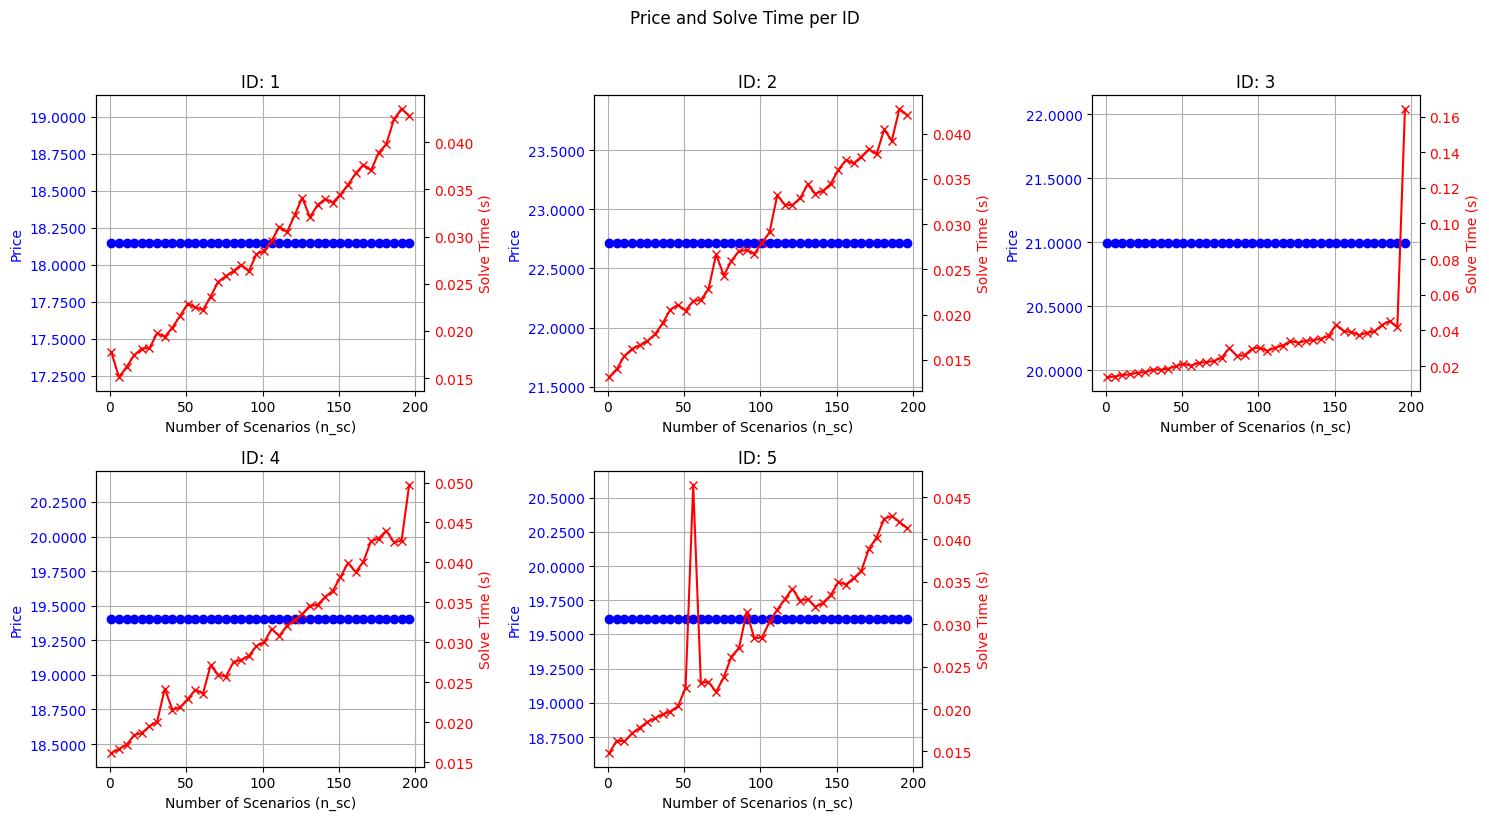

In [32]:
experiment_price_n_sc_solve_time(trainer, use_means=True, n_ids=5, end_range=200)

&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Processing ID: 1 (1/5)
16.23299066696101
n_sc=1: price=16.2330, time=0.0362s
16.232990666960994
n_sc=6: price=16.2330, time=0.0446s
16.23299066696101
n_sc=11: price=16.2330, time=0.0517s
16.232990666960998
n_sc=16: price=16.2330, time=0.0509s
16.23299066696101
n_sc=21: price=16.2330, time=0.0550s
16.23299066696101
n_sc=26: price=16.2330, time=0.0565s
16.23299066696101
n_sc=31: price=16.2330, time=0.0617s
16.23299066696101
n_sc=36: price=16.2330, time=0.0612s
16.23299066696101
n_sc=41: price=16.2330, time=0.0695s
16.23299066696101
n_sc=46: price=16.2330, time=0.0668s
16.231870604357123
n_sc=51: price=16.2319, time=0.1001s
16.23299066696101
n_sc=56: price=16.2330, time=0.0810s
16.23299066696101
n_sc=61: price=16.2330, time=0.0780s
16.231870604357123
n_sc=66: price=16.2319, time=0.0860s
16.231870604357123
n_sc=71: price=16.2319, time=0.1070s
16.231870604357123
n_sc=76: price=16.2319, time=0.0914s
16.23299066696101
n_sc=81: price=16.2330, 

C:\Users\danie\AppData\Local\Temp\ipykernel_53760\3015678385.py:96: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['price'] = data['price'].round(4)


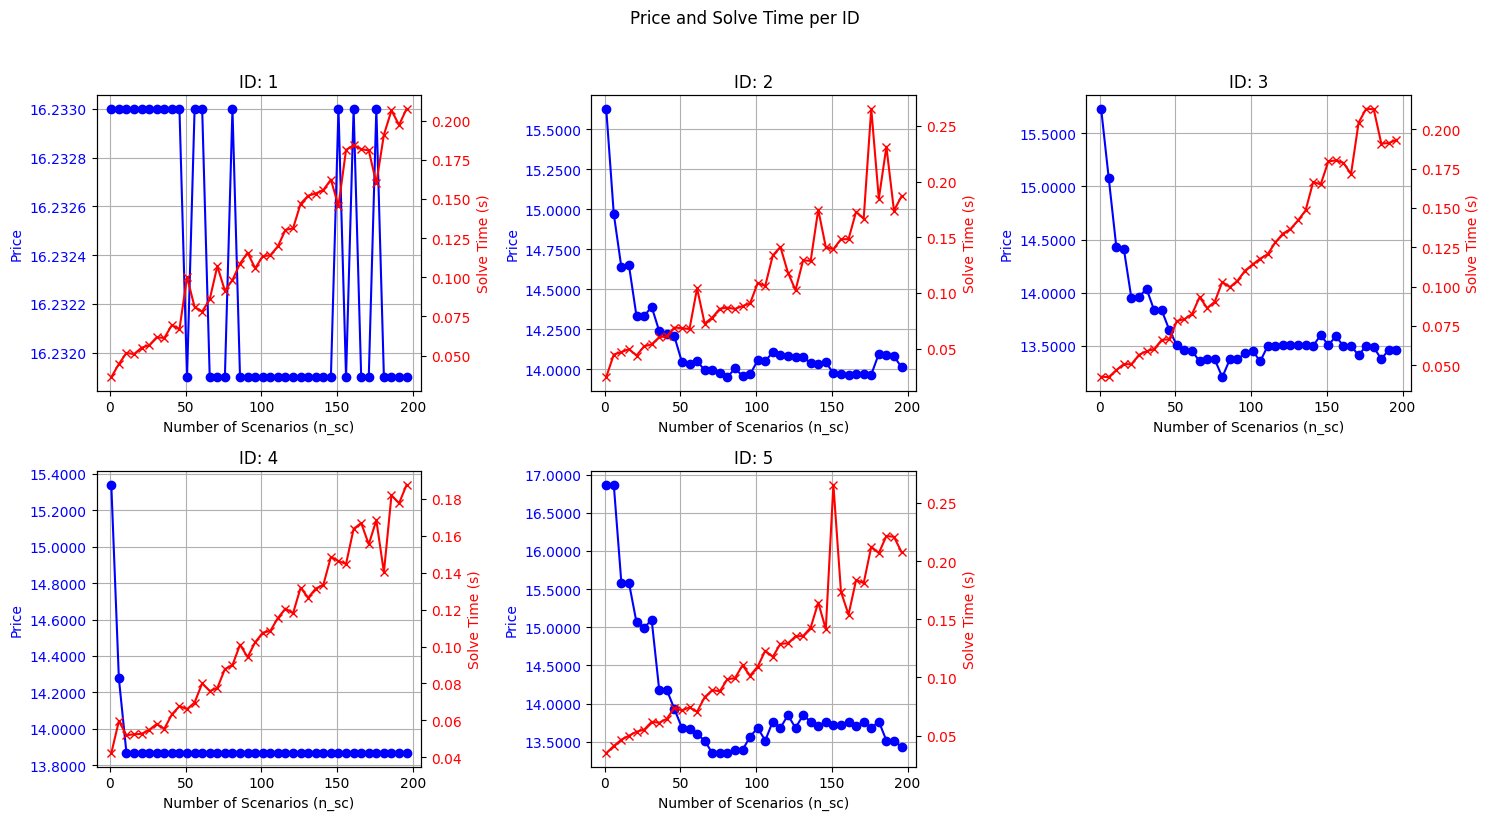

In [33]:
experiment_price_n_sc_solve_time(trainer, use_means=False, n_ids=5, end_range=200)

Running with n_preds = 1
  Solve time = 0.04 seconds
Running with n_preds = 2
  Solve time = 0.04 seconds
Running with n_preds = 3
  Solve time = 0.09 seconds
Running with n_preds = 4
  Solve time = 0.15 seconds
Running with n_preds = 5
  Solve time = 0.46 seconds
Running with n_preds = 6
  Solve time = 0.23 seconds
Running with n_preds = 7
  Solve time = 0.30 seconds
Running with n_preds = 8
  Solve time = 0.40 seconds
Running with n_preds = 9
  Solve time = 0.47 seconds
Running with n_preds = 10
  Solve time = 2.66 seconds
Running with n_preds = 11
  Solve time = 2.22 seconds
Running with n_preds = 12
  Solve time = 2.31 seconds
Running with n_preds = 13
  Solve time = 2.75 seconds
Running with n_preds = 14
  Solve time = 4.31 seconds
Running with n_preds = 15
  Solve time = 4.16 seconds
Running with n_preds = 16
  Solve time = 4.33 seconds
Running with n_preds = 17
  Solve time = 6.09 seconds
Running with n_preds = 18
  Solve time = 4.28 seconds
Running with n_preds = 19
  Solve tim

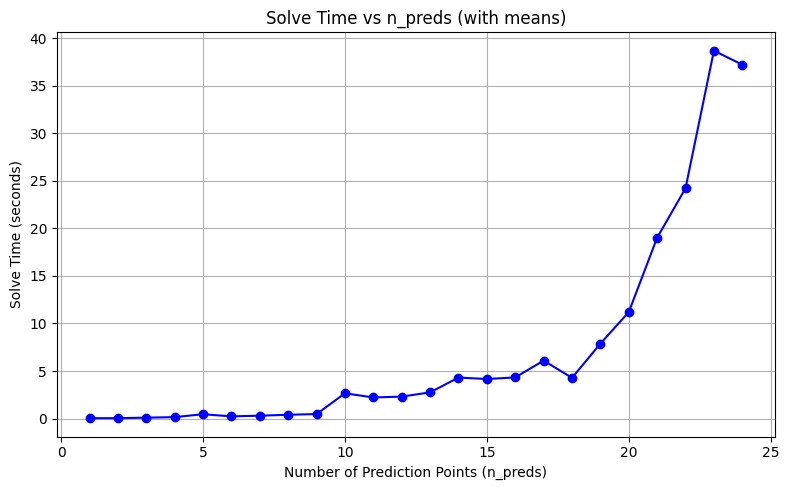

Plot saved to: imgs/solve_time_vs_n_preds_with_means_50_ids_25_n_sc.png


In [35]:
experiment_solve_time_vs_n_preds(trainer, use_means=True, n_sc=50, end_range=25)

Running with n_preds = 1


  Solve time = 0.09 seconds
Running with n_preds = 2
  Solve time = 0.39 seconds
Running with n_preds = 3
  Solve time = 1.28 seconds
Running with n_preds = 4
  Solve time = 3.37 seconds
Running with n_preds = 5
  Solve time = 22.53 seconds
Running with n_preds = 6
  Solve time = 35.73 seconds
Running with n_preds = 7
  Solve time = 216.54 seconds
Running with n_preds = 8
  Solve time = 421.81 seconds
Running with n_preds = 9
  Solve time = 5948.27 seconds


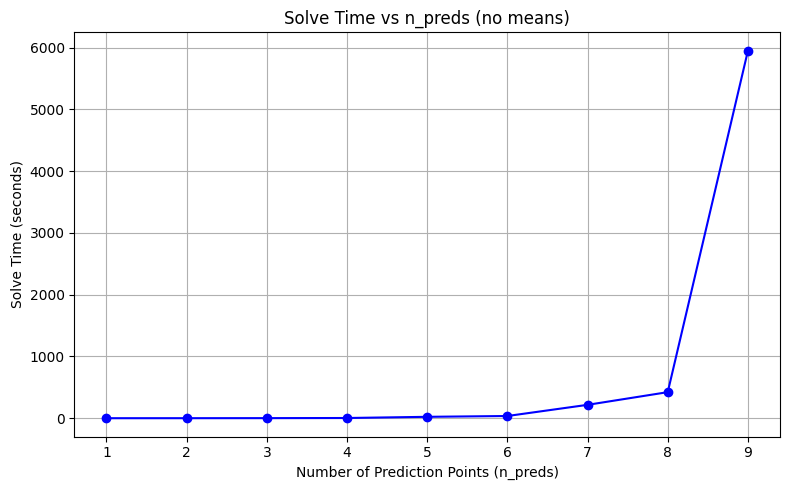

Plot saved to: imgs/solve_time_vs_n_preds_no_means_50_ids_10_n_sc.png


In [14]:
experiment_solve_time_vs_n_preds(trainer, use_means=False, n_sc=50, end_range=10)